In [75]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import time
import gget
import anndata as an
import scanpy as sc
import scanpy.external as sce
import h5py
import scipy
from scipy.stats import median_abs_deviation
from scipy.stats import pearsonr
from gseapy.parser import download_library
import gseapy as gp
import textwrap
from collections import Counter

sc.settings.verbosity = 2
# sc.logging.print_header()

# Load in processed anndata

In [11]:
start = time.perf_counter()

path = "/scratch/indikar_root/indikar1/shared_data/HYB/anndata/condition_subsets/mmMYOD1_controls_processed.h5ad"

adata = sc.read_h5ad(path)

sc.logging.print_memory_usage() 
print(f"Total time: {time.perf_counter() - start:.2f} seconds")

adata

Memory usage: current 6.11 GB, difference +4.97 GB
Total time: 3.35 seconds


AnnData object with n_obs × n_vars = 9167 × 23037
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', 'leiden_split', 'S_score', 'G2M_score', 'phase', 'cluster_vs_control'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'filter_pass', 'highly_variable', 'means', 'dispersions', 'dispe

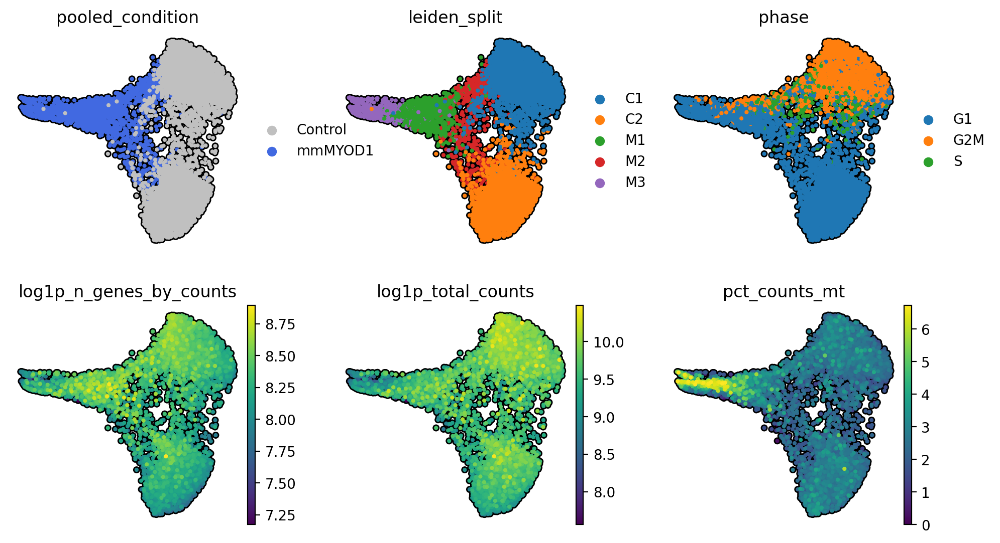

In [15]:
plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 3, 3

sc.pl.draw_graph(
    adata,
    color=['pooled_condition', 'leiden_split', 'phase', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_mt'],
    ncols=3,
    size=35,
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    alpha=1,
)

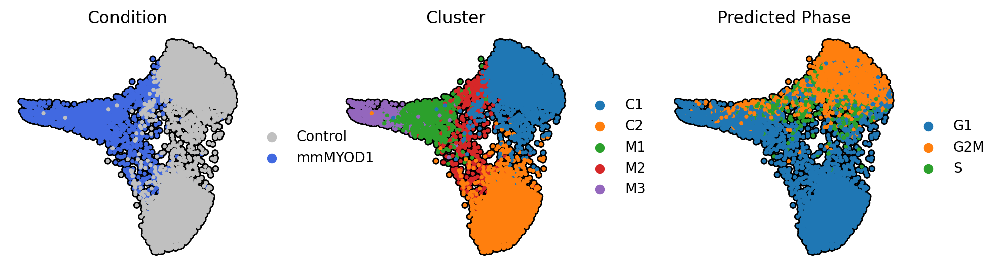

In [80]:
plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 3, 3

sc.pl.draw_graph(
    adata,
    color=['pooled_condition', 'leiden_split', 'phase'],
    ncols=3,
    size=35,
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    alpha=1,
    title=["Condition", "Cluster", "Predicted Phase"],
    hspace=0.5,
)

# Get DEGs

adata.uns['deg_all_clusters'] --> each cluster vs union of the rest (how is each cluster different from the rest of the clusters?)

adata.uns['deg_cluster_vs_control'] --> each mmMYOD1 cluster vs controls (how are each of the mmMYOD1 clusters different from control cells?)

adata.uns['deg_myod_vs_control'] --> all mmMYOD1 cells vs controls (how are all mmMYOD1 cells different from control cells?)

In [ ]:
# sc.pl.rank_genes_groups_dotplot(
#     adata,
#     groups=['C1', 'C2', 'M1', 'M2', 'M3'],
#     key='deg_all_clusters',
#     values_to_plot='logfoldchanges',
#     cmap='bwr',
#     n_genes=5,
#     vmin=-3,
#     vmax=3,
#     min_logfoldchange=1,
# )

In [12]:
deg = sc.get.rank_genes_groups_df(
    adata, 
    group=None,
    key='deg_cluster_vs_control',
)

print(deg.shape)
deg.head()

(69111, 7)


,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group
0,M1,MYOD1,51.056034,32.242527,0.0,0.0,1.000000
1,M1,MT-ND4,51.050079,2.745996,0.0,0.0,1.000000
2,M1,IFIT3,45.171288,2.013302,0.0,0.0,0.998993
3,M1,TAF1D,44.272617,2.851606,0.0,0.0,0.965760
4,M1,LINC-PINT,43.459896,2.689616,0.0,0.0,0.969789


In [13]:
def get_significant_DEGs(df, alpha=0.05, logfc_thresh=0.5, pct_nz_thresh=0.0):
    
    """ Filters DGE results for significant differentially expressed genes. 
    
    Params
    ------
        df (pd.DataFrame): Dataframe containing DGE results.
        alpha (float): Adjusted p-value threshold for statistical significance. Genes below this threshold are considered significant.
        logfc_thresh (float): Minimum absolute logfoldchange required for a gene to be considered significantly DE. 
        pct_nz_thresh (float): Minimum proportion of cells in the group of interest expressing the gene. Genes expressed in fewer cells than this threshold will be excluded.
    
    """
    
    tmp = df.copy()
    
    print(f"Filtering for significant DEGs (adjusted p-value < {alpha}, logfoldchange > {logfc_thresh})...")

    tmp['abs_lfc'] = tmp['logfoldchanges'].apply('abs')
    tmp = tmp[(tmp['abs_lfc'] > logfc_thresh) & (tmp['pvals_adj'] < alpha)]
    tmp = tmp[tmp['pct_nz_group'] > pct_nz_thresh]
    
    if pct_nz_thresh != 0.0:
        print(f"Removed genes expressed in less than {pct_nz_thresh*100}% of cells.")
    
    print(f"N unique significant DEGs: {tmp['names'].nunique()}\n")
    
    return tmp


sig = get_significant_DEGs(deg)
sig.head()

Filtering for significant DEGs (adjusted p-value < 0.05, logfoldchange > 0.5)...
N unique significant DEGs: 9972



,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,abs_lfc
0,M1,MYOD1,51.056034,32.242527,0.0,0.0,1.000000,32.242527
1,M1,MT-ND4,51.050079,2.745996,0.0,0.0,1.000000,2.745996
2,M1,IFIT3,45.171288,2.013302,0.0,0.0,0.998993,2.013302
3,M1,TAF1D,44.272617,2.851606,0.0,0.0,0.965760,2.851606
4,M1,LINC-PINT,43.459896,2.689616,0.0,0.0,0.969789,2.689616


In [21]:
print("Top marker genes per mmMYOD1 cluster (sorted by 'scores'):")
pd.DataFrame(adata.uns['deg_cluster_vs_control']['names'][:10])

Top marker genes per mmMYOD1 cluster (sorted by 'scores'):


,M1,M2,M3
0,MYOD1,MYOD1,MYOD1
1,MT-ND4,MT-ND4,MT-ND4
2,IFIT3,NAV3,PPP1R15A
3,TAF1D,IFIT3,TAF1D
4,LINC-PINT,LINC-PINT,RUNX1
5,IFIT1,ISG15,LINC-PINT
6,IFIT2,IFIT1,NAV3
7,NAV3,SMURF2,GADD45A
8,XAF1,RSAD2,RSRC2
9,RIGI,KCNQ5,TRIO


Removing non protein-coding, unnamed, and mitochondrial genes...
N unique DE protein-coding genes: 8455



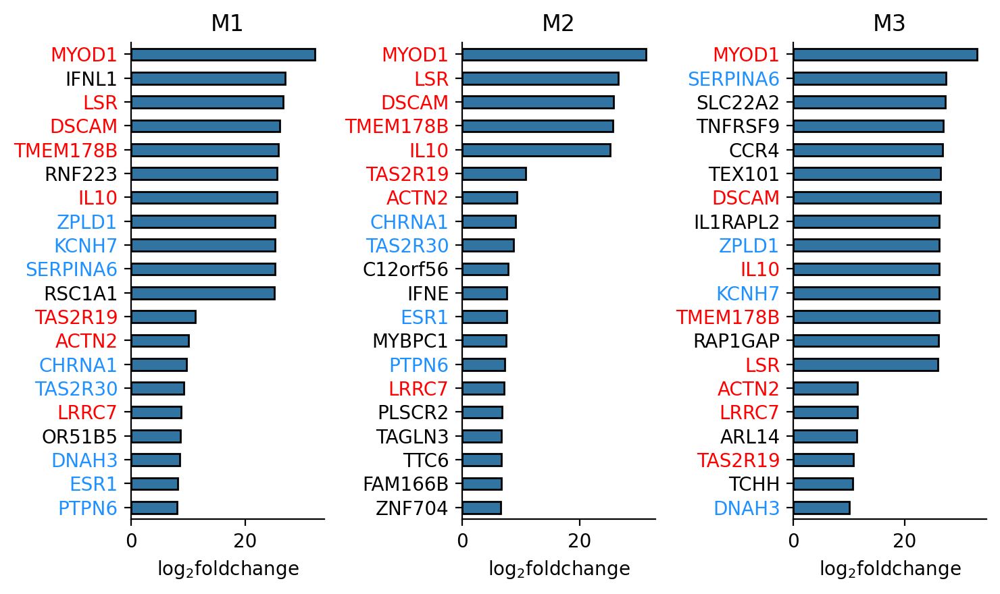

In [77]:
gdf = adata.var[['gene_type', 'mt', 'ribo']].copy()
gdf = gdf.reset_index(names='names')

pdf = pd.merge(sig, gdf, how='left', on='names')

print("Removing non protein-coding, unnamed, and mitochondrial genes...")

pdf = pdf[pdf['gene_type'] == 'protein_coding'] # get only protein-coding genes
pdf = pdf[~pdf['names'].str.startswith(('ENSG', 'MT-'))] # remove unnamed and MT genes

print(f"N unique DE protein-coding genes: {pdf['names'].nunique()}\n")

pdf = pdf.sort_values(by=['group', 'logfoldchanges'], ascending=[True, False])


plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 7.5, 4.5

fig, axs = plt.subplots(nrows=1, ncols=3)

n_genes = 20

plot_order = ['M1', 'M2', 'M3']

top_genes_per_group = {}

for group in plot_order:
    df = pdf[pdf['group'] == group].sort_values(by='logfoldchanges', ascending=False)
    top_genes_per_group[group] = df.head(n_genes)['names'].tolist()

# Step 2: Count appearances across groups
gene_counts = Counter()
for gene_list in top_genes_per_group.values():
    gene_counts.update(gene_list)

# Step 3: Categorize genes
red_genes = {gene for gene, count in gene_counts.items() if count == 3}
blue_genes = {gene for gene, count in gene_counts.items() if count == 2}

for i, group in enumerate(plot_order): 
    df = pdf[pdf['group'] == group].sort_values(by='logfoldchanges', ascending=False).head(n_genes)
    ax = axs[i]

    sns.barplot(data=df, x='logfoldchanges', y='names', ax=ax, width=0.5, ec='k')
    ax.set_title(group)
    ax.set_xlabel("log$_2$foldchange")
    ax.set_ylabel("")

    # if group == 'mmMYOD1':
    #     ax.set_xlim([0, 10])
    #     # ax.set_xscale('log')
    # elif group == 'siPRRX1/mmMYOD1':
    #     ax.set_xlim([0, 6])
    #     # ax.set_xscale('log')
    # else:
    #     ax.set_xlim([0, 5])

    for tick in ax.get_yticklabels():
        gene = tick.get_text()
        if gene in red_genes:
            tick.set_color('red')
        elif gene in blue_genes:
            tick.set_color('dodgerblue')

sns.despine()
plt.tight_layout()
plt.show()

# Gene scoring

Proliferation / cell cycle

Quiescence

Asymmetric cell division (NUMB/NOTCH)

### Get genesets for scoring

In [22]:
# GO cell cycle genes
fpath = "../../resources/human_cell_cycle_genes.csv"
cdf = pd.read_csv(fpath)
cdf.head()

,gene_name,G1 Phase,G1/S Transition Checkpoint Signaling,G2 Phase,G2/M Transition Checkpoint Signaling,M Phase,S Phase
0,ABCB1,False,False,False,True,False,False
1,ACVR1B,False,True,False,False,False,False
2,AMBRA1,False,True,False,False,False,False
3,APP,False,False,False,True,False,False
4,ARPP19,False,False,False,True,False,False


In [27]:
### GO biological processes
path_2023 = "../resources/GO_Biological_Process_2023.txt"
path_2025 = "/home/jrcwycy/.cache/gseapy/Enrichr.GO_Biological_Process_2025.gmt"

geneset_dict = {}

with open(path_2025, "r") as f:
    for line in f:
        parts = line.strip().split('\t')
        if len(parts) >= 1:
            term = parts[0].strip()
            genes = parts[2:] if len(parts) > 2 else []
            genes = [g.strip() for g in genes if g.strip()]
            geneset_dict[term] = genes

geneset = pd.DataFrame.from_dict(geneset_dict, orient='index').T

# [col for col in geneset if "asymmetric" in col.lower()]

pos_prolif = geneset[[
    'Positive Regulation of Fibroblast Proliferation (GO:0048146)',
    'Positive Regulation of Cell Population Proliferation (GO:0008284)',
]]

neg_prolif = geneset[[
    'Negative Regulation of Fibroblast Proliferation (GO:0048147)',
    'Negative Regulation of Cell Population Proliferation (GO:0008285)',
]]

In [51]:
# G1/S
g1s_transition = geneset[[
    'G1/S Transition of Mitotic Cell Cycle (GO:0000082)',
    'Cell Cycle G1/S Phase Transition (GO:0044843)',
    'Regulation of G1/S Transition of Mitotic Cell Cycle (GO:2000045)',
    'Regulation of Cell Cycle G1/S Phase Transition (GO:1902806)',
]]

checkpoint_signaling = geneset[[
    'Mitotic G1 DNA Damage Checkpoint Signaling (GO:0031571)',
    'Mitotic G1/S Transition Checkpoint Signaling (GO:0044819)',
    'Mitotic G2 DNA Damage Checkpoint Signaling (GO:0007095)',
    'Mitotic G2/M Transition Checkpoint (GO:0044818)',
    'Mitotic Cell Cycle Checkpoint Signaling (GO:0007093)',
    'Regulation of Cell Cycle Checkpoint (GO:1901976)',
]]

g2m_transition = geneset[[
    'G2/M Transition of Mitotic Cell Cycle (GO:0000086)',
    'Cell Cycle G2/M Phase Transition (GO:0044839)',
    'Regulation of G2/M Transition of Mitotic Cell Cycle (GO:0010389)',
]]

general_cc = geneset[[
    'Regulation of Cell Cycle (GO:0051726)',
    'Regulation of Cell Cycle Process (GO:0010564)',
]]

In [50]:
[col for col in geneset if "g0" in col.lower()]

['Regulation of G0 to G1 Transition (GO:0070316)']

In [28]:
# read in quiescence genes
fpath = "../../resources/genes_for_scoring.csv"
df = pd.read_csv(fpath, index_col=0)
print(df.columns.tolist())

qdf = df[['Quiescence_TFs']]
qdf.head()

['TFs', 'Fibroblasts', 'Myofibroblasts', 'Myogenic', 'cell_cycle', 'AS', 'Circadian', 'Core_reprogramming', 'Senescence_GO', 'Senescence_UP', 'Senescence_DOWN', 'DNA_damage', 'Chromatin_remodeling', 'TF_activity', 'Pos_apoptosis', 'Neg_apoptosis', 'Quiescence_TFs']


,Quiescence_TFs
0,ATF3
1,ATF4
2,CTNNB1
3,BACH2
4,JUN


In [31]:
database = "Reactome_Pathways_2024"

library = download_library(database)

library = pd.DataFrame.from_dict(library, orient='index').T
library.head()

,2-LTR Circle Formation,A Tetrasaccharide Linker Sequence Is Required for GAG Synthesis,ABC Transporter Disorders,ABC Transporters in Lipid Homeostasis,ABC-family Proteins Mediated Transport,ADORA2B Mediated Anti-Inflammatory Cytokines Production,ADP Signalling Through P2Y Purinoceptor 1,ADP Signalling Through P2Y Purinoceptor 12,AKT Phosphorylates Targets in the Cytosol,AKT Phosphorylates Targets in the Nucleus,...,tRNA Aminoacylation,tRNA Modification in the Mitochondrion,tRNA Modification in the Nucleus and Cytosol,tRNA Processing,tRNA Processing in the Mitochondrion,tRNA Processing in the Nucleus,"tRNA-derived Small RNA (tsRNA or tRNA-related Fragment, tRF) Biogenesis",trans-Golgi Network Vesicle Budding,vRNA Synthesis,vRNP Assembly
0,REV,B3GAT3,ABCG8,ABCA2,ABCC4,GNG13,PLA2G4A,P2RY12,CDKN1B,CREB1,...,MARS1,TRIT1,TRMT10A,PUS3,TRMT10C,SEC13,TRP-AGG1-1,SNAPIN,PA,PA
1,XRCC5,B3GAT2,ABCC2,ABCG8,ABCG8,GNG12,GNG13,GNG13,GSK3B,RPS6KB2,...,HARS2,TRMT10C,NSUN2,CPSF1,ELAC2,CPSF1,TRR-CCG1-1,AP1S1,NP,NP
2,XRCC6,B3GAT1,KCNJ11,ABCA3,ABCC5,CREB1,GNG12,GNAI1,GSK3A,AKT3,...,RARS1,TRMU,PUS3,TYW5,TRNT1,CPSF4,TRA-TGC1-1,HSPA8,NS,HSP90AA1
3,XRCC4,BGN,ABCC8,ABCD3,ABCC2,IL6,MAPK14,GNG12,BAD,AKT1,...,HARS1,PRORP,TRIT1,CPSF4,MT-ATP8,ELAC2,TRV-AAC1-1,YIPF6,PARP1,NS
4,PSIP1,B3GALT6,ABCC9,PEX19,PEX19,ADORA2B,GNB1,GNAI2,CDKN1A,AKT2,...,RARS2,PUS1,METTL1,NUP214,MT-TA,NDC1,ELAC2,AP1B1,PB2,IPO5


In [38]:
notch_signaling = ['Signaling by NOTCH', 'Signaling by NOTCH1', 'Signaling by NOTCH2', 'Signaling by NOTCH3', 'Signaling by NOTCH4']

notch_df = library[notch_signaling]
notch_df.head()

,Signaling by NOTCH,Signaling by NOTCH1,Signaling by NOTCH2,Signaling by NOTCH3,Signaling by NOTCH4
0,H2AZ2,PSENEN,PSENEN,PSENEN,PSENEN
1,EGF,TLE4,JAG1,EGF,FBXW7
2,RUNX1,FBXW7,JAG2,KAT2B,RBX1
3,H2BC12L,TLE3,GZMB,KAT2A,ACTA2
4,NOTCH2NLB,TLE2,ADAM10,NEURL1,KAT2B


In [37]:
[col for col in library if "division" in col.lower()]

[]

In [52]:
categories = {
    # "G1": cdf.loc[cdf['G1 Phase'] == True, 'gene_name'].unique().tolist(),
    # "G1/S_checkpoint": cdf.loc[cdf['G1/S Transition Checkpoint Signaling'] == True, 'gene_name'].unique().tolist(),
    # "S": cdf.loc[cdf['S Phase'] == True, 'gene_name'].unique().tolist(),
    # "G2": cdf.loc[cdf['G2 Phase'] == True, 'gene_name'].unique().tolist(),
    # "G2/M_checkpoint": cdf.loc[cdf['G2/M Transition Checkpoint Signaling'] == True, 'gene_name'].unique().tolist(),
    # "M": cdf.loc[cdf['M Phase'] == True, 'gene_name'].unique().tolist(),
    
    "G1/S_transition": list(set(g1s_transition.stack().unique().tolist())),
    "G2/M_transition": list(set(g2m_transition.stack().unique().tolist())),
    "CC_checkpoints": list(set(checkpoint_signaling.stack().unique().tolist())),
    "Cell_cycle_reg": list(set(general_cc.stack().unique().tolist())),
    "Pos_proliferation": list(set(pos_prolif.stack().unique().tolist())),
    "Neg_proliferation": list(set(neg_prolif.stack().unique().tolist())),
    "quiescence": qdf['Quiescence_TFs'].unique(),
    "NOTCH_signaling": list(set(notch_df.stack().unique().tolist())),
}

for key, gene_list in categories.items():
    print(f"N genes for {key}: {len(gene_list)}")
    
# make into a dataframe
cleaned_categories = {k: list(np.ravel(v)) for k, v in categories.items()}
max_len = max(len(v) for v in cleaned_categories.values())
padded = {k: v + [None] * (max_len - len(v)) for k, v in cleaned_categories.items()}

df = pd.DataFrame(padded)
df.head()

N genes for G1/S_transition: 196
N genes for G2/M_transition: 72
N genes for CC_checkpoints: 71
N genes for Cell_cycle_reg: 431
N genes for Pos_proliferation: 484
N genes for Neg_proliferation: 379
N genes for quiescence: 60
N genes for NOTCH_signaling: 209


,G1/S_transition,G2/M_transition,CC_checkpoints,Cell_cycle_reg,Pos_proliferation,Neg_proliferation,quiescence,NOTCH_signaling
0,INHBA,CDC7,MUC1,PTK6,HCK,INHBA,ATF3,PSMD8
1,SMARCC2,CDK4,MRNIP,TP73,PRKCI,PHF14,ATF4,PLXND1
2,KIF14,KIF14,CRY1,THAP5,PRTN3,TP73,CTNNB1,PSMC6
3,PRMT2,CCNA2,TAOK2,PPP1R13B,WNT1,CHD6,BACH2,PSMD1
4,CUL5,ARPP19,DGKZ,ECT2,PRAME,ATG101,JUN,PRKCI


### Score genes

computing score 'All_G1/S_transition_score'
    finished (0:00:01)
computing score 'DE_G1/S_transition_score'
    finished (0:00:01)
computing score 'All_G2/M_transition_score'
    finished (0:00:01)
computing score 'DE_G2/M_transition_score'
    finished (0:00:01)
computing score 'All_CC_checkpoints_score'
    finished (0:00:01)
computing score 'DE_CC_checkpoints_score'
    finished (0:00:01)
computing score 'All_Cell_cycle_reg_score'
    finished (0:00:01)
computing score 'DE_Cell_cycle_reg_score'
    finished (0:00:01)
computing score 'All_Pos_proliferation_score'
    finished (0:00:01)
computing score 'DE_Pos_proliferation_score'
    finished (0:00:01)
computing score 'All_Neg_proliferation_score'
    finished (0:00:01)
computing score 'DE_Neg_proliferation_score'
    finished (0:00:01)
computing score 'All_quiescence_score'
    finished (0:00:01)
computing score 'DE_quiescence_score'
    finished (0:00:01)
computing score 'All_NOTCH_signaling_score'
    finished (0:00:01)
computin

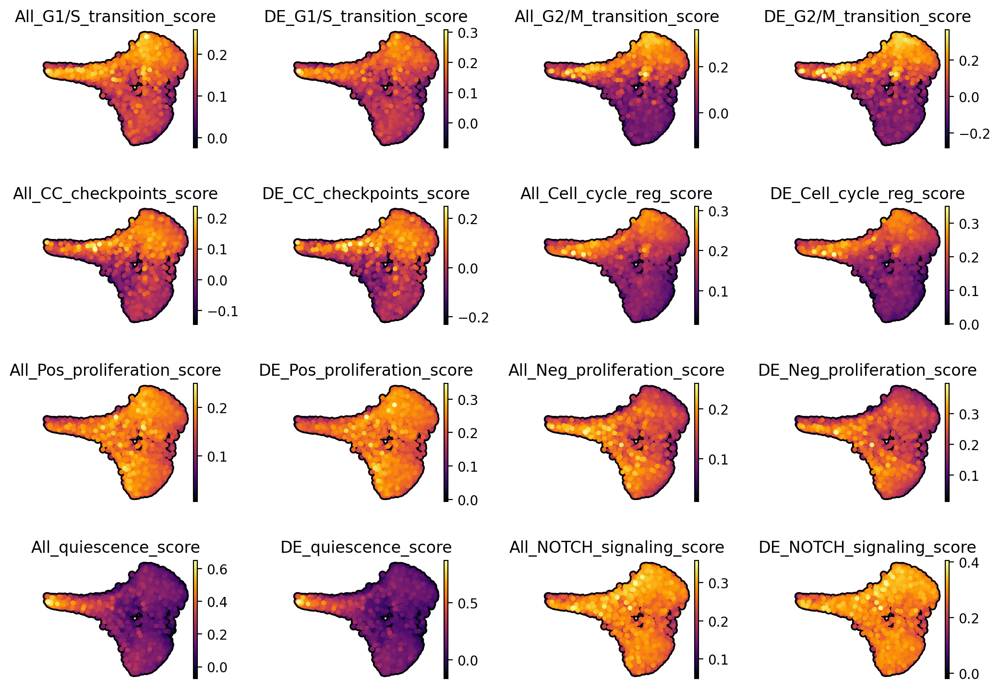

In [53]:
min_ctrl_size = 500

for geneset in df.columns:    
    
    all_score_name = f"All_{geneset}_score"
    de_score_name = f"DE_{geneset}_score"
    
    # Skip if scores already exist
    if all_score_name in adata.obs.columns and de_score_name in adata.obs.columns:
        print(f"Skipping {geneset}, scores already exist.")
        continue
        
    # get all genes belonging to geneset
    all_gene_list = df[geneset].unique()
    all_gene_list = [gene for gene in all_gene_list if gene in adata.var_names]
    
    # get DE geneset genes from adata
    sig_genes = sig['names'].unique()
    de_gene_list = [gene for gene in sig_genes if gene in all_gene_list]
    
    # Set the ctrl_size to either 500 or the length of the gene list (whichever is larger)
    all_ctrl_size = max(min_ctrl_size, len(all_gene_list)) 
    de_ctrl_size = max(min_ctrl_size, len(de_gene_list))
    
    # Score ALL genes in geneset
    sc.tl.score_genes(
        adata,
        gene_list=all_gene_list,
        score_name=all_score_name,
        ctrl_size=all_ctrl_size,
        use_raw=False,
        layer='log_norm',
    )

    # Score just DE genes in geneset
    sc.tl.score_genes(
        adata,
        gene_list=de_gene_list,
        score_name=de_score_name,
        ctrl_size=de_ctrl_size,
        use_raw=False,
        layer='log_norm',
    )
    
print("Finished.")

scores_to_plot = [col for col in adata.obs if col.startswith(('DE', 'All'))]
print(len(scores_to_plot))

plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = 2, 2

sc.pl.draw_graph(
    adata,
    color=scores_to_plot,
    size=50,
    ncols=4,
    add_outline=True,
    outline_color=('k', 'k'),
    color_map='inferno',
    frameon=False,
    alpha=1,
    show=True,
    hspace=0.5,
    wspace=0.5,
)

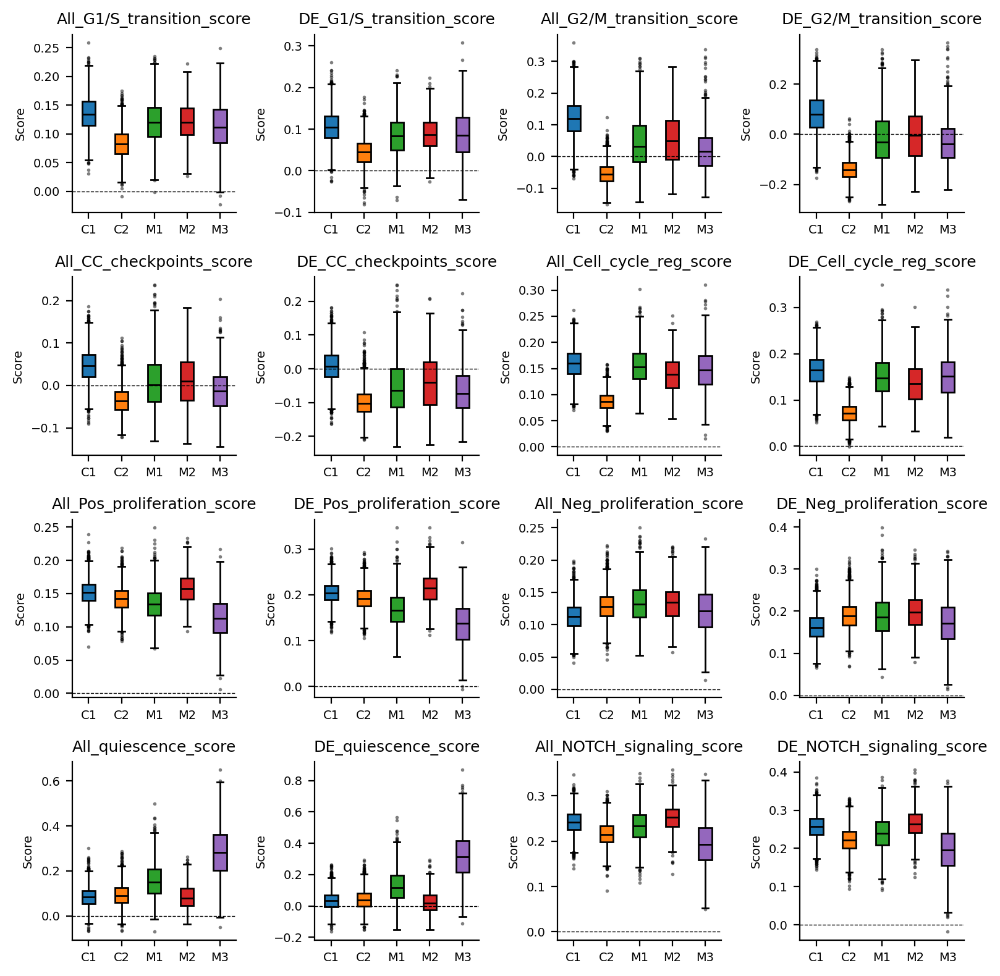

In [78]:
ncols = 4
nrows = round(len(scores_to_plot)/ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(8, 8), dpi=200)
axes = axes.flatten()

for i, score in enumerate(scores_to_plot):
    ax = axes[i]
    
    title = score
    
    sns.boxplot(
        data=adata.obs,
        x='leiden_split',
        y=score,
        width=0.4,
        linecolor='k',
        hue='leiden_split',
        # palette=color_map,
        legend=False,
        saturation=1,
        flierprops={'markersize': 1, 'alpha': 0.5},
        ax=ax,
        zorder=0,
    )
    
    ax.axhline(0, linestyle='--', linewidth=0.5, color='k', zorder=1)
    
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("")
    # ax.xticks(fontsize=7)
    ax.set_ylabel("Score", fontsize=7)
    ax.tick_params(axis='both', labelsize=7)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

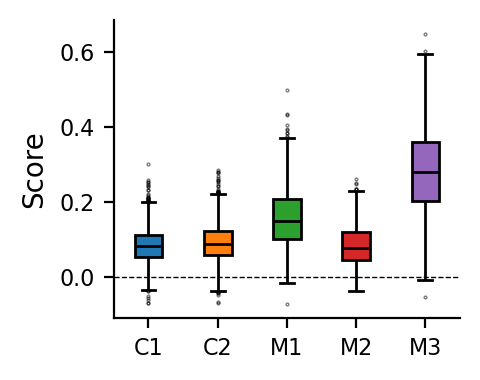

In [82]:
plt.rcParams['figure.figsize'] = 2.5, 2

sns.boxplot(
    data=adata.obs,
    x='leiden_split',
    hue='leiden_split',
    y='All_quiescence_score',
    width=0.4,
    linecolor='k',
    linewidth=1,
    legend=False,
    saturation=1,
    flierprops={'markersize': 0.5, 'alpha': 0.5},
    zorder=1,
)

plt.axhline(0, linestyle='--', linewidth=0.5, color='k', zorder=0)

plt.ylabel('Score')
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.xlabel("")
sns.despine()

plt.tight_layout()
plt.show() 

# Notch

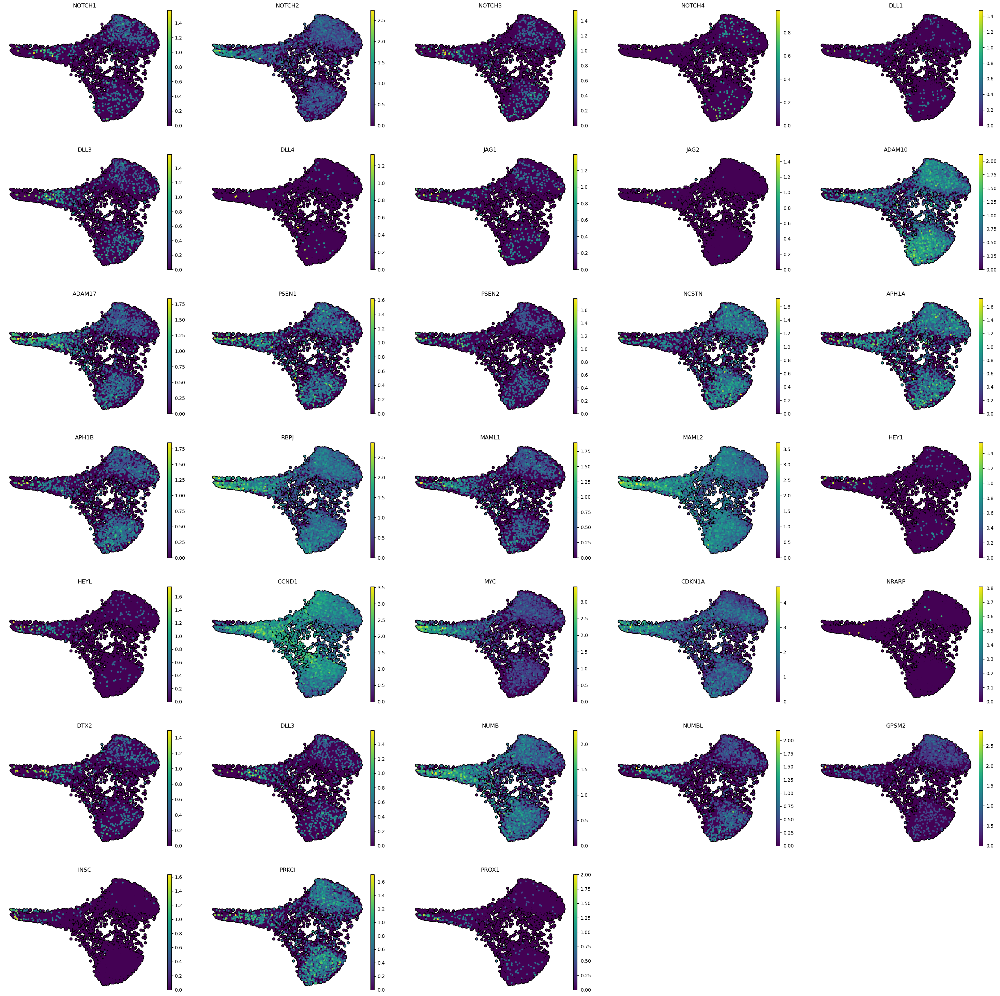

In [83]:
genes_to_plot = [
    'NOTCH1', 'NOTCH2', 'NOTCH3', 'NOTCH4', 'DLL1', 'DLL3', 'DLL4', 'JAG1', 'JAG2', # core Notch signaling components
    'ADAM10', 'ADAM17', 'PSEN1', 'PSEN2', 'NCSTN', 'APH1A', 'APH1B', 'PEN2', 'NICD', 'RBPJ', 'MAML1', 'MAML2', 'MAML3' # Notch signal transduction/activation
    'HES1', 'HES5', 'HEY1', 'HEY2', 'HEYL', 'CCND1', 'MYC', 'CDKN1A', 'NRARP', 'DTX1', 'DTX2', 'DLL3', # Canonical Notch targets
    'NUMB', 'NUMBL',
    'LGN', 'GPSM2', 'INSC', 'PAR3', 'PAR6', 'PRKCI',
    'ASCI1', 'SOX2', 'PROX1',
]

genes_to_plot = [gene for gene in genes_to_plot if gene in adata.var_names]

plt.rcdefaults()
sc.pl.draw_graph(
    adata,
    color=genes_to_plot,
    ncols=5,
    size=60,
    add_outline=True,
    outline_color=('k', 'k'),
    frameon=False,
    alpha=1,
    layer='log_norm',
)

# IGNORE BELOW

In [160]:
database = "WikiPathways_2024_Human"

library = download_library(database)

library = pd.DataFrame.from_dict(library, orient='index').T
library.head()

,SRF And miRs In Smooth Muscle Differentiation And Proliferation WP1991,TCA Cycle And Deficiency Of Pyruvate Dehydrogenase Complex PDHc WP2453,Mammary Gland Development Pathway Embryonic Development Stg 1/4 WP2813,Initiation Of Transcription And Translation Elongation HIV1 LTR WP3414,Hypothesized Pathways In Pathogenesis Of Cardiovascular Disease WP3668,TGF Beta In Thyroid Cells For Epithelial Mesenchymal Transition WP3859,Development Of Pulmonary Dendritic Cells And Macrophage Subsets WP3892,mRNA Protein And Metabolite Inducation Pathway By Cyclosporin A WP3953,Somatroph Axis GH Relationship To Dietary Restriction And Aging WP4186,Chromosomal And Microsatellite Instability In Colorectal Cancer WP4216,...,Ferroptosis WP4313,IL2 Signaling WP49,Cholestasis WP5238,GPCRs Other WP117,Cori Cycle WP1946,ID Signaling WP53,Cell Cycle WP179,Autophagy WP4923,Apoptosis WP254,Melanoma WP4685
0,MEF2B,FH,TGFB1,CREBBP,SMAD3,SMAD3,BATF3,SLC7A5,AKT1,TGFB1,...,ACSL3,STAT5B,ABCC4,GPR17,G6PD,SREBF1,TGFB1,ATG3,MAP3K1,BAD
1,CAMK2D,IDH1,ITGB1,HEXIM1,POSTN,SMAD2,SPI1,KEAP1,PTEN,RHOA,...,GPX4,MAP2K2,ABCG8,GPR18,TPI1,RB1,TGFB3,ATG9A,JUN,MITF
2,MEF2A,PDHA1,TNF,NFATC4,SMAD2,SMAD4,CSF2,SLC3A2,SIRT1,CSNK1A1,...,ACSL1,STAT1,ABCB4,HTR1F,PGAM1,PAX5,TGFB2,UVRAG,SCAF11,BRAF
3,MEF2D,DLST,NRG3,NFATC3,SMAD4,FN1,CSF1,SLC1A5,MTOR,TGFB3,...,NCOA4,CISH,ABCC2,GPR55,SLC2A1,MYOD1,ZBTB17,WIPI2,APAF1,CDK6
4,MEF2C,CS,SFRP1,NFATC2,ANGPT2,TNC,STAT3,SLC7A11,IGF1R,JUN,...,GSS,MAP2K1,ABCC3,OR1F1,SLC2A2,ELK1,CDC25A,PRKAB1,BAD,PIK3CB


In [161]:
[col for col in library if 'notch' in col.lower()]

['Apoptosis Related Network Due To Altered Notch3 Ovarian Cancer WP2864',
 'NOTCH1 Regulation Of Endothelial Cell Calcification WP3413',
 'Canonical And Non Canonical Notch Signaling WP3845',
 'Notch Signaling WP268',
 'Notch Signaling WP61']

N Notch signaling genes: 74

computing score 'All_Notch_score'
    finished (0:00:01)


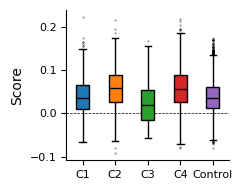

In [163]:
notch_terms = [
    'Canonical And Non Canonical Notch Signaling WP3845',
    'Notch Signaling WP268',
    'Notch Signaling WP61',
]
ndf = library[notch_terms]
notch_genes = list(set(ndf.stack().tolist()))
notch_genes = [gene for gene in notch_genes if gene in bdata.var_names]
print(f"N Notch signaling genes: {len(notch_genes)}\n")


sc.tl.score_genes(
    bdata,
    gene_list=notch_genes,
    score_name='All_Notch_score',
    ctrl_size=500,
    use_raw=False,
    layer='log_norm',
)


plt.rcParams['figure.figsize'] = 2.5, 2

sns.boxplot(
    data=bdata.obs,
    x='cluster_group',
    hue='cluster_group',
    y='All_Notch_score',
    width=0.4,
    linecolor='k',
    linewidth=1,
    legend=False,
    saturation=1,
    flierprops={'markersize': 0.5, 'alpha': 0.5},
    zorder=1,
)

plt.axhline(0, linestyle='--', linewidth=0.5, color='k', zorder=0)

plt.ylabel('Score')
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.xlabel("")
sns.despine()

plt.tight_layout()
plt.show()

In [29]:
database = "Reactome_Pathways_2024"

library = download_library(database)

library = pd.DataFrame.from_dict(library, orient='index').T
library.head()

,2-LTR Circle Formation,A Tetrasaccharide Linker Sequence Is Required for GAG Synthesis,ABC Transporter Disorders,ABC Transporters in Lipid Homeostasis,ABC-family Proteins Mediated Transport,ADORA2B Mediated Anti-Inflammatory Cytokines Production,ADP Signalling Through P2Y Purinoceptor 1,ADP Signalling Through P2Y Purinoceptor 12,AKT Phosphorylates Targets in the Cytosol,AKT Phosphorylates Targets in the Nucleus,...,tRNA Aminoacylation,tRNA Modification in the Mitochondrion,tRNA Modification in the Nucleus and Cytosol,tRNA Processing,tRNA Processing in the Mitochondrion,tRNA Processing in the Nucleus,"tRNA-derived Small RNA (tsRNA or tRNA-related Fragment, tRF) Biogenesis",trans-Golgi Network Vesicle Budding,vRNA Synthesis,vRNP Assembly
0,REV,B3GAT3,ABCG8,ABCA2,ABCC4,GNG13,PLA2G4A,P2RY12,CDKN1B,CREB1,...,MARS1,TRIT1,TRMT10A,PUS3,TRMT10C,SEC13,TRP-AGG1-1,SNAPIN,PA,PA
1,XRCC5,B3GAT2,ABCC2,ABCG8,ABCG8,GNG12,GNG13,GNG13,GSK3B,RPS6KB2,...,HARS2,TRMT10C,NSUN2,CPSF1,ELAC2,CPSF1,TRR-CCG1-1,AP1S1,NP,NP
2,XRCC6,B3GAT1,KCNJ11,ABCA3,ABCC5,CREB1,GNG12,GNAI1,GSK3A,AKT3,...,RARS1,TRMU,PUS3,TYW5,TRNT1,CPSF4,TRA-TGC1-1,HSPA8,NS,HSP90AA1
3,XRCC4,BGN,ABCC8,ABCD3,ABCC2,IL6,MAPK14,GNG12,BAD,AKT1,...,HARS1,PRORP,TRIT1,CPSF4,MT-ATP8,ELAC2,TRV-AAC1-1,YIPF6,PARP1,NS
4,PSIP1,B3GALT6,ABCC9,PEX19,PEX19,ADORA2B,GNB1,GNAI2,CDKN1A,AKT2,...,RARS2,PUS1,METTL1,NUP214,MT-TA,NDC1,ELAC2,AP1B1,PB2,IPO5


In [30]:
[col for col in library if 'notch' in col.lower()]

['Activated NOTCH1 Transmits Signal to the Nucleus',
 'Constitutive Signaling by NOTCH1 HD Domain Mutants',
 'Constitutive Signaling by NOTCH1 HD+PEST Domain Mutants',
 'Constitutive Signaling by NOTCH1 PEST Domain Mutants',
 'Constitutive Signaling by NOTCH1 t(7;9)(NOTCH1 M1580 K2555) Translocation Mutant',
 'FBXW7 Mutants and NOTCH1 in Cancer',
 'Loss of Function of FBXW7 in Cancer and NOTCH1 Signaling',
 'NOTCH1 Intracellular Domain Regulates Transcription',
 'NOTCH2 Activation and Transmission of Signal to the Nucleus',
 'NOTCH2 Intracellular Domain Regulates Transcription',
 'NOTCH3 Activation and Transmission of Signal to the Nucleus',
 'NOTCH3 Intracellular Domain Regulates Transcription',
 'NOTCH4 Activation and Transmission of Signal to the Nucleus',
 'NOTCH4 Intracellular Domain Regulates Transcription',
 'Negative Regulation of NOTCH4 Signaling',
 'Noncanonical Activation of NOTCH3',
 'Notch-HLH Transcription Pathway',
 'Pre-NOTCH Expression and Processing',
 'Pre-NOTCH Proc

N Notch signaling genes: 73

computing score 'All_SASP_score'
    finished (0:00:01)


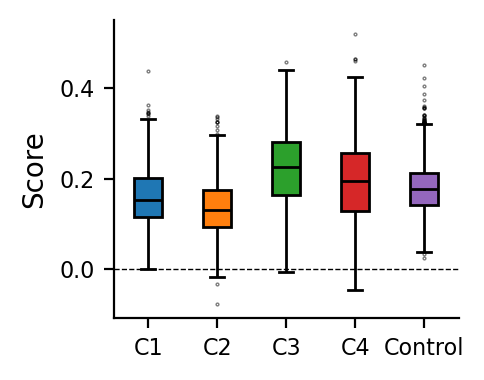

In [206]:
sasp_terms = ['Senescence-Associated Secretory Phenotype (SASP)']
sdf = library[sasp_terms]
sasp_genes = list(set(sdf.stack().tolist()))
sasp_genes = [gene for gene in sasp_genes if gene in bdata.var_names]
print(f"N Notch signaling genes: {len(sasp_genes)}\n")


sc.tl.score_genes(
    bdata,
    gene_list=sasp_genes,
    score_name='All_SASP_score',
    ctrl_size=500,
    use_raw=False,
    layer='log_norm',
)


plt.rcParams['figure.figsize'] = 2.5, 2

sns.boxplot(
    data=bdata.obs,
    x='cluster_group',
    hue='cluster_group',
    y='All_SASP_score',
    width=0.4,
    linecolor='k',
    linewidth=1,
    legend=False,
    saturation=1,
    flierprops={'markersize': 0.5, 'alpha': 0.5},
    zorder=1,
)

plt.axhline(0, linestyle='--', linewidth=0.5, color='k', zorder=0)

plt.ylabel('Score')
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.xlabel("")
sns.despine()

plt.tight_layout()
plt.show()

In [170]:
# sc.tl.rank_genes_groups(
#     bdata, 
#     groupby="cluster_group",
#     method='wilcoxon',
#     corr_method='benjamini-hochberg',
#     use_raw=False,
#     layer='log_norm',
#     pts=True,
#     key_added='cluster_deg',
# )

deg = sc.get.rank_genes_groups_df(
    bdata, 
    group=None,
    key='cluster_vs_control',
)

print(deg.shape)

sig = get_significant_DEGs(deg)
sig.head()

(92148, 7)
Filtering for significant DEGs (adjusted p-value < 0.05, logfoldchange > 0.5)...
N unique significant DEGs: 10508



,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,abs_lfc
0,C1,MYOD1,48.408413,31.502670,0.0,0.0,1.000000,31.502670
1,C1,MT-ND4,48.222820,2.560445,0.0,0.0,1.000000,2.560445
2,C1,IFIT3,42.644882,1.794097,0.0,0.0,1.000000,1.794097
3,C1,NAV3,42.164425,3.246546,0.0,0.0,0.954545,3.246546
4,C1,LINC-PINT,41.098656,2.494576,0.0,0.0,0.979545,2.494576


In [175]:
print(pd.DataFrame({g: bdata.uns['cluster_vs_control']['names'][g][:10] for g in bdata.uns['cluster_vs_control']['names'].dtype.names}))

          C1         C2        C3         C4
0      MYOD1      MYOD1     MYOD1      MYOD1
1     MT-ND4     MT-ND4    MT-ND4     MT-ND4
2      IFIT3      TAF1D  PPP1R15A   PPP1R15A
3       NAV3  LINC-PINT     RSRC2      TAF1D
4  LINC-PINT      IFIT3     RUNX1       NAV3
5      IFIT1     RSL1D1    PMAIP1  LINC-PINT
6      ISG15      IFIT2      ATF3    GADD45A
7     SMURF2       IRF1    RASAL2      RSRC2
8      RSAD2      IFIT1   GADD45A      TXNIP
9       RIGI       XAF1     HDAC9     JMJD1C


In [174]:
tmp = sig[sig['names'].isin(notch_genes)]
print(tmp['names'].nunique())
print(tmp['names'].unique())

51
['NFKB1' 'MAML2' 'JAK2' 'ITCH' 'NUMB' 'DTX3L' 'GSK3B' 'CREBBP' 'NCOR2'
 'MAML3' 'ADAM17' 'MTOR' 'APH1A' 'FBXW7' 'CHUK' 'TLE1' 'SAP30' 'HDAC1'
 'MFAP2' 'ADAM10' 'FHL1' 'RRAS' 'HES1' 'SNW1' 'CIR1' 'NCOR1' 'SPEN'
 'EP300' 'MFAP1' 'RBPJ' 'CUL1' 'PIK3R1' 'MAML1' 'DLL3' 'NUMBL' 'PSEN1'
 'DTX3' 'SRC' 'PIK3R2' 'NCSTN' 'PSENEN' 'DNER' 'CTBP1' 'RING1' 'DVL3'
 'AKT1' 'HDAC2' 'SKP1' 'NOTCH2' 'APH1B' 'CTBP2']


In [173]:
tmp[tmp['names'] == 'NUMB']

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,abs_lfc
531,C1,NUMB,13.339447,1.075167,1.364677e-40,3.540322e-39,0.593182,1.075167
23690,C2,NUMB,12.418074,1.281002,2.085216e-35,3.966731e-34,0.585538,1.281002
70464,C4,NUMB,7.840876,1.072529,4.474135e-15,3.130943e-14,0.455505,1.072529


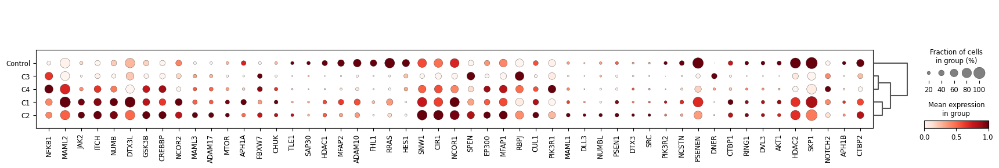

In [180]:
sc.pl.rank_genes_groups_dotplot(
    bdata,
    groups=['C1', 'C2', 'C3', 'C4'],
    var_names=tmp['names'].unique(),
    key='cluster_vs_control',
    standard_scale='var',
    # values_to_plot='logfoldchanges',
)

In [181]:
gdf = bdata.var[['gene_type', 'mt', 'ribo']].copy()
gdf = gdf.reset_index(names='names')

pdf = pd.merge(sig, gdf, how='left', on='names')

print("Removing non protein-coding, unnamed, and mitochondrial genes...")

pdf = pdf[pdf['gene_type'] == 'protein_coding'] # get only protein-coding genes
pdf = pdf[~pdf['names'].str.startswith(('ENSG', 'MT-'))] # remove unnamed and MT genes
# pdf = pdf[~pdf['ribo']] # remove ribosomal genes

print(f"N unique DE protein-coding genes: {pdf['names'].nunique()}\n")

pdf = pdf.sort_values(by=['group', 'logfoldchanges'], ascending=[True, False])
pdf.groupby('group', observed=True)[['group', 'names', 'logfoldchanges']].head(3)

Removing non protein-coding, unnamed, and mitochondrial genes...
N unique DE protein-coding genes: 8939



,group,names,logfoldchanges
0,C1,MYOD1,31.502670
1316,C1,LSR,26.711725
3470,C1,IFNL1,26.108086
5046,C2,MYOD1,32.476315
8386,C2,LSR,26.337887
8819,C2,TMEM178B,26.120031
11925,C3,MYOD1,33.071877
12340,C3,SLC22A2,30.004848
12946,C3,DNAI1,29.749741
17312,C4,MYOD1,32.844238


In [188]:
up = pdf[pdf['logfoldchanges'] > 0]
up.groupby('group', observed=True)['names'].nunique()

group
C1    3369
C2    4483
C3    1507
C4    3015
Name: names, dtype: int64

# GSEA

Running Enrichment on C1 group with 500 genes using database: Reactome_Pathways_2024...
Significant terms for C1: 15
(alpha = 0.01)


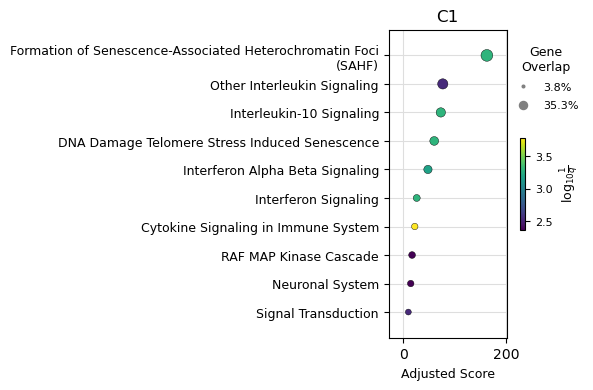

Running Enrichment on C2 group with 500 genes using database: Reactome_Pathways_2024...
Significant terms for C2: 2
(alpha = 0.01)


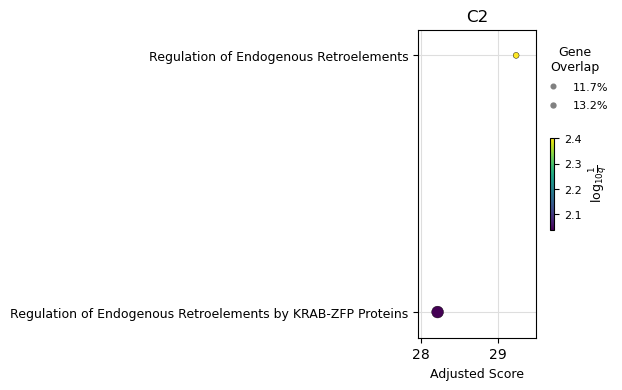

Running Enrichment on C3 group with 500 genes using database: Reactome_Pathways_2024...
Significant terms for C3: 0
(alpha = 0.01)
No significant terms found for condition: C3. Skipping plot.
Running Enrichment on C4 group with 500 genes using database: Reactome_Pathways_2024...
Significant terms for C4: 68
(alpha = 0.01)


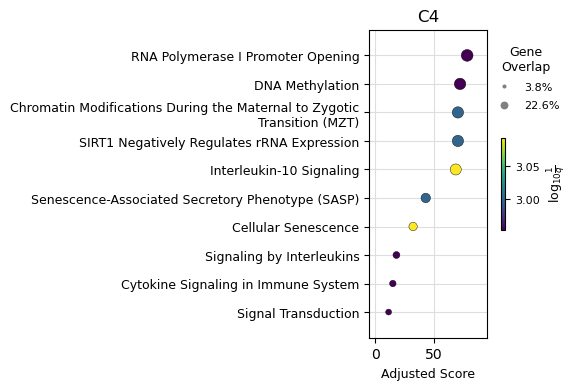

In [192]:
conditions_to_plot = ['C1', 'C2', 'C3', 'C4']

n_genes = 500 
database="GO_Biological_Process_2025"
database="Reactome_Pathways_2024"
# database="KEGG_2021_Human"
# database = "CellMarker_2024"
# database = "TF_Perturbations_Followed_by_Expression"
# database = "WikiPathways_2024_Human"
# database='GO_Molecular_Function_2025'
# database='MSigDB_Hallmark_2020' # interesting
# database='Tabula_Sapiens'
n_terms = 10
alpha = 0.01

# Loop through each condition to generate a separate plot
for condition in conditions_to_plot:
    print(f"Running Enrichment on {condition} group with {n_genes} genes using database: {database}...")

    # Filter pdf for the current condition and get gene list
    tmp = pdf[pdf['group'] == condition]
    tmp = tmp.sort_values(by='logfoldchanges', ascending=False)
    gene_list = tmp['names'].head(n_genes).to_list()


    enr = gp.enrichr(
        gene_list=gene_list,
        gene_sets=database,
        organism='human', # Or 'mouse' if appropriate for your data
        outdir=None, # Prevents writing results to disk, if not desired
    )
    edf = enr.results.copy()


    # Filter for significant terms
    # Ensure there are significant terms before proceeding to plotting
    if not edf.empty:
        edf = edf[edf['Adjusted P-value'] < alpha].copy()
        print(f"Significant terms for {condition}: {edf['Term'].nunique()}\n(alpha = {alpha})")

        if edf.empty:
            print(f"No significant terms found for condition: {condition}. Skipping plot.")
            continue # Skip to the next condition if no significant terms

        # Create plotting columns
        overlap_split = edf["Overlap"].str.split("/", expand=True).astype(int)
        edf['Overlap_pct'] = (100 * overlap_split[0] / overlap_split[1]).round(1)
        edf['log10_adj_pval'] = np.log10(1 / edf['Adjusted P-value'])
        # Remove (GO:...) and (Reactome:...) identifiers from term names
        edf['Term'] = edf['Term'].str.replace(r'\s\(GO:\d+\)', '', regex=True)
        edf['Term'] = edf['Term'].str.replace(r'\s\(Reactome:R-HSA-\d+\)', '', regex=True)

        # Calculate combined score with adjusted p-val
        edf['adj_score'] = -np.log(edf['Adjusted P-value']) * edf['Odds Ratio']

        # Get top n terms sorted by significance (Adjusted P-value)
        edf = edf.sort_values(by='Adjusted P-value', ascending=True).head(n_terms).copy()

        # Sort by adjusted combined score for plotting (descending)
        edf = edf.sort_values(by='adj_score', ascending=False).copy()

        # --- Plotting Code for current condition ---
        # Create a new figure and axes for each plot in the loop
        fig, ax = plt.subplots(figsize=(2, 4))

        sns.scatterplot(
            data=edf,
            x='adj_score',
            y='Term',
            ec='k', # Edge color
            linewidth=0.3,
            hue='log10_adj_pval', # Color by log10(1/Adjusted P-value)
            palette='viridis', # Color map
            size='Overlap_pct', # Size of points by overlap percentage
            zorder=3, # Ensures scatter points are on top of grid
            ax=ax # Explicitly pass the axes object to seaborn
        )

        x_margin = 0.25
        y_margin = 0.1
        ax.margins(x=x_margin, y=y_margin)

        # Add grid
        ax.grid(
            True,
            c='#DEDEDE', # Grid color
            zorder=0, # Ensures grid is behind scatter points
        )

        ax.set_ylabel("")

        # --- Y-tick label wrapping ---
        original_ylabels = edf['Term'].to_list()
        wrap_width = 60 # Adjust this width as needed for your plot size and text length
        wrapped_ylabels = [textwrap.fill(label, wrap_width) for label in original_ylabels]
        ax.set_yticklabels(wrapped_ylabels, fontsize=9)
        # --- End of Y-tick label wrapping ---

        # Colorbar for log10_adj_pval
        norm = plt.Normalize(edf['log10_adj_pval'].min(), edf['log10_adj_pval'].max())
        sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
        sm.set_array([])
        # `fig.colorbar` is used with `ax` to attach it to the current axes' figure
        cbar = fig.colorbar(sm, ax=ax, orientation='vertical', pad=0.09, shrink=0.3)
        cbar.set_label('log$_{10} \\frac{1}{q}$', fontsize='9')
        cbar.ax.tick_params(labelsize=8)

        # Overlap percentage legend
        min_overlap = edf['Overlap_pct'].min()
        max_overlap = edf['Overlap_pct'].max()

        # Scaling for legend handles to match scatterplot point sizes
        scaled_min_size = min_overlap * 3 # Adjust multiplier (3) to match visual size
        scaled_max_size = max_overlap * 3 # Adjust multiplier (3) to match visual size

        legend_handles = [
            plt.Line2D([0], [0], marker='o', color='gray', label=f'{min_overlap:.1f}%',
                       markersize=np.sqrt(scaled_min_size / np.pi), linestyle=''),
            plt.Line2D([0], [0], marker='o', color='gray', label=f'{max_overlap:.1f}%',
                       markersize=np.sqrt(scaled_max_size / np.pi), linestyle='')
        ]

        # Gene Overlap legend setup
        legend = ax.legend(handles=legend_handles, title='Gene\nOverlap',
                            loc='upper right', # Location of the legend
                            bbox_to_anchor=(1.7, 0.98), # Position relative to the axes (adjusted for space)
                            fontsize=8, title_fontsize=9, frameon=False, labelspacing=0.75)


        legend_title = legend.get_title()
        legend_title.set_ha('center')
        ax.set_xlabel("Adjusted Score", fontsize=9)
        ax.set_title(f"{condition}")
        plt.tight_layout(rect=[0, 0, 1.4, 1])
        plt.show()

In [2]:
# start = time.perf_counter()

# path = "/nfs/turbo/umms-indikar/shared/projects/hybrid_reprogramming/anndata/raw_merged_gene_data.h5ad"

# adata_raw = sc.read_h5ad(path)

# sc.logging.print_memory_usage() 
# print(f"Total time: {time.perf_counter() - start:.2f} seconds")

# print(f"Initial shape: {adata_raw.shape}\n")
# print(f"N cells in HYB dataset: {adata_raw[adata_raw.obs['dataset'] == 'Hybrid'].n_obs}")
# print(f"N cells in scFib dataset: {adata_raw[adata_raw.obs['dataset'] == 'Control'].n_obs}\n")

# adata_raw

Memory usage: current 1.14 GB, difference +1.14 GB
Total time: 1.01 seconds
Initial shape: (19858, 28702)

N cells in HYB dataset: 10895
N cells in scFib dataset: 8963



AnnData object with n_obs × n_vars = 19858 × 28702
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End'

In [3]:
# ### --- Handle HYB cells with NaN feature barcode predictions ---
# init_cells_hybrid = adata_raw[adata_raw.obs['dataset'] == 'Hybrid'].n_obs

# # remove HYB cells with NaN feature barcode predictions
# hybrid_to_remove = (adata_raw.obs['dataset'] == 'Hybrid') & (adata_raw.obs['assigned_condition'].isna())
# cells_to_keep = ~(hybrid_to_remove)
# adata_raw = adata_raw[cells_to_keep].copy()

# final_cells_hybrid = adata_raw[adata_raw.obs['dataset'] == 'Hybrid'].n_obs
# removed_hybrid_cells = init_cells_hybrid - final_cells_hybrid

# print(f"Removed {removed_hybrid_cells} 'Hybrid' cells with unassigned feature barcodes")
# print(f"Final shape: {adata_raw.shape}")

# ### --- Add new column for grouping HYB cells vs Controls ---
# adata_raw.obs['pooled_condition'] = adata_raw.obs['assigned_condition'].replace({
#     "G1": "Control",
#     "S": "Control",
#     "G2M": "Control",
#     "PRRX1": "siPRRX1",
#     "PRRX1_MYOD": "siPRRX1/mmMYOD1",
#     "MYOD": "mmMYOD1"
# })

# # fill remaining NaN feature barcode predictions (only control cells) with 'Control'
# adata_raw.obs['pooled_condition'] = adata_raw.obs['pooled_condition'].fillna('Control')
# print(adata_raw.obs['pooled_condition'].value_counts())

# adata_raw

Removed 1 'Hybrid' cells with unassigned feature barcodes
Final shape: (19857, 28702)
pooled_condition
Control            8963
siPRRX1/mmMYOD1    4174
siPRRX1            3955
mmMYOD1            2765
Name: count, dtype: int64


/tmp/ipykernel_2732478/2282474984.py:16: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata_raw.obs['pooled_condition'] = adata_raw.obs['assigned_condition'].replace({


AnnData object with n_obs × n_vars = 19857 × 28702
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End'

In [4]:
# print("Subsetting adata for mmMYOD1 cells with positive MYOD1 expression + Controls...\n")

# init_cells = adata_raw.n_obs

# # Extract MYOD1 expression as a dense 1D array
# myod1_expr = adata_raw[:, 'MYOD1'].X.toarray().flatten()

# # Create a mask for mmMYOD1 cells with non-zero MYOD1 expression and controls
# cells_to_keep = ((adata_raw.obs['pooled_condition'] == 'mmMYOD1') & (myod1_expr > 0)) | (adata_raw.obs['dataset'] == 'Control')

# adata = adata_raw[cells_to_keep].copy()

# final_cells = adata.n_obs

# print(f"Removed {init_cells - final_cells} cells. \nFinal cells in adata: {final_cells}")

# adata

Subsetting adata for mmMYOD1 cells with positive MYOD1 expression + Controls...

Removed 8387 cells. 
Final cells in adata: 11470


AnnData object with n_obs × n_vars = 11470 × 28702
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End'

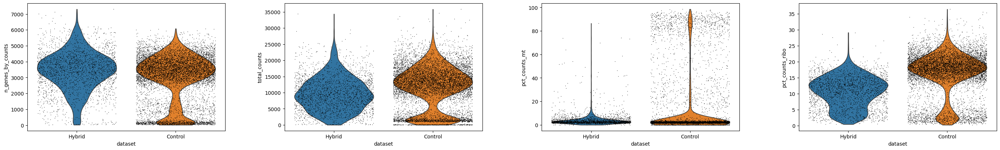

Number of outlier cells per dataset based on counts:
dataset
Hybrid      131
Control    1676
Name: outlier, dtype: int64

Number of outlier cells per dataset based on pct mito:
Total number of cells: 11470
N cells in Hybird: 2507
N cells in Control: 8963

Filtering...

Removed 2303 total cells.
Removed 300 from Hybrid dataset.
Removed 2003 from Control dataset.

Total cells after filtering of low quality cells: 9167
N cells in Hybird: 2207
N cells in Control: 6960


In [5]:
# # mitochondrial genes
# adata.var["mt"] = adata.var_names.str.startswith("MT-")
# # ribosomal genes
# adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))

# sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"], inplace=True, log1p=True)

# plt.rcdefaults()
# sc.pl.violin(
#     adata,
#     ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"],
#     jitter=0.4,
#     multi_panel=True,
#     groupby='dataset',
# )

# # Identify outlier cells with MADs per dataset
# def is_outlier_by_group(adata, metric: str, nmads: int, group_col: str = 'dataset'):
#     outlier_series = pd.Series(False, index=adata.obs.index)
#     unique_groups = adata.obs[group_col].unique()

#     for group in unique_groups:
#         group_mask = (adata.obs[group_col] == group)
#         M_group = adata.obs.loc[group_mask, metric]

#         if len(M_group) < 2 or M_group.isnull().all():
#             continue

#         median_val_group = np.median(M_group)
#         mad_val_group = median_abs_deviation(M_group)

#         if mad_val_group == 0:
#             continue

#         outliers_in_group = (M_group < median_val_group - nmads * mad_val_group) | \
#                             (median_val_group + nmads * mad_val_group < M_group)

#         outlier_series.loc[group_mask] = outliers_in_group

#     return outlier_series


# adata.obs["outlier"] = (
#     is_outlier_by_group(adata, "log1p_total_counts", 5, 'dataset')
#     | is_outlier_by_group(adata, "log1p_n_genes_by_counts", 5, 'dataset')
# )

# print("Number of outlier cells per dataset based on counts:")
# print(adata.obs.groupby('dataset', observed=True)['outlier'].sum())


# adata.obs["mt_outlier"] = is_outlier_by_group(adata, "pct_counts_mt", 5, 'dataset') | (
#     adata.obs["pct_counts_mt"] > 20
# )

# print("\nNumber of outlier cells per dataset based on pct mito:")
# adata.obs.groupby('dataset', observed=True)['mt_outlier'].sum()

# init_cells = adata.n_obs
# init_cells_hyb = adata[adata.obs['dataset'] == 'Hybrid'].n_obs
# init_cells_fib = adata[adata.obs['dataset'] == 'Control'].n_obs

# print(f"Total number of cells: {init_cells}")
# print(f"N cells in Hybird: {init_cells_hyb}")
# print(f"N cells in Control: {init_cells_fib}")

# print(f"\nFiltering...")
# adata = adata[(~adata.obs.outlier) & (~adata.obs.mt_outlier)].copy()

# final_cells = adata.n_obs
# final_cells_hyb = adata[adata.obs['dataset'] == 'Hybrid'].n_obs
# final_cells_fib = adata[adata.obs['dataset'] == 'Control'].n_obs

# print(f"\nRemoved {init_cells - final_cells} total cells.")
# print(f"Removed {init_cells_hyb - final_cells_hyb} from Hybrid dataset.")
# print(f"Removed {init_cells_fib - final_cells_fib} from Control dataset.")

# print(f"\nTotal cells after filtering of low quality cells: {final_cells}")
# print(f"N cells in Hybird: {final_cells_hyb}")
# print(f"N cells in Control: {final_cells_fib}")

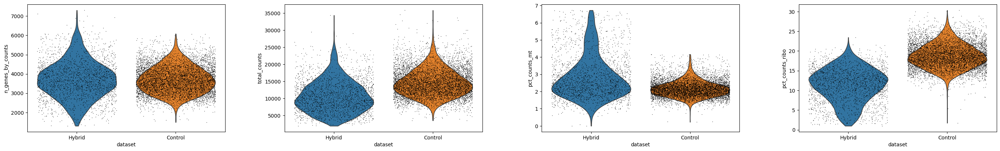

In [26]:
# sc.pl.violin(
#     adata,
#     ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"],
#     jitter=0.4,
#     multi_panel=True,
#     groupby='dataset',
# )

In [6]:
# # keep full dimension safe
# adata.raw = adata  

# # save raw counts
# adata.layers['raw_counts'] = adata.X.copy()

# sc.pp.filter_genes(adata, min_counts=10)

# sc.pp.normalize_total(
#     adata,
#     target_sum=1e4,
# )

# # save normalized counts
# adata.layers['norm_counts'] = adata.X.copy()

# # log transform normalized counts
# sc.pp.log1p(adata)

# # save log normalized counts
# adata.layers['log_norm'] = adata.X.copy()

# adata

filtered out 5665 genes that are detected in less than 10 counts
normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 9167 × 23037
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts'
    uns: 'dataset_colors', 'log1p'
    layers: 'raw_counts', 'norm_counts', 'log_norm'

In [7]:
# adata.var['filter_pass'] = True # set the gene filter

# # disallow GO cell cycle genes
# fpath = "../../resources/human_cell_cycle_genes.csv"
# cdf = pd.read_csv(fpath)
# adata.var['filter_pass'] = np.where(adata.var.index.isin(cdf['gene_name'].unique()), False, adata.var['filter_pass'])

# # disallow Regev cell cycle genes
# fpath = "../../resources/regev_lab_cell_cycle_genes.txt"
# genes = [x.strip() for x in open(fpath)]
# adata.var['filter_pass'] = np.where(adata.var.index.isin(genes), False, adata.var['filter_pass'])

# # disallow mitochondrial and ribosomal genes
# adata.var['filter_pass'] = np.where(adata.var.index.str.startswith('MT'), False, adata.var['filter_pass'])
# adata.var['filter_pass'] = np.where(adata.var.index.str.startswith('RP'), False, adata.var['filter_pass'])

# print(adata.var['filter_pass'].value_counts().to_string())

filter_pass
True     22600
False      437


extracting highly variable genes
    finished (0:00:02)
Number of HVG: 2353


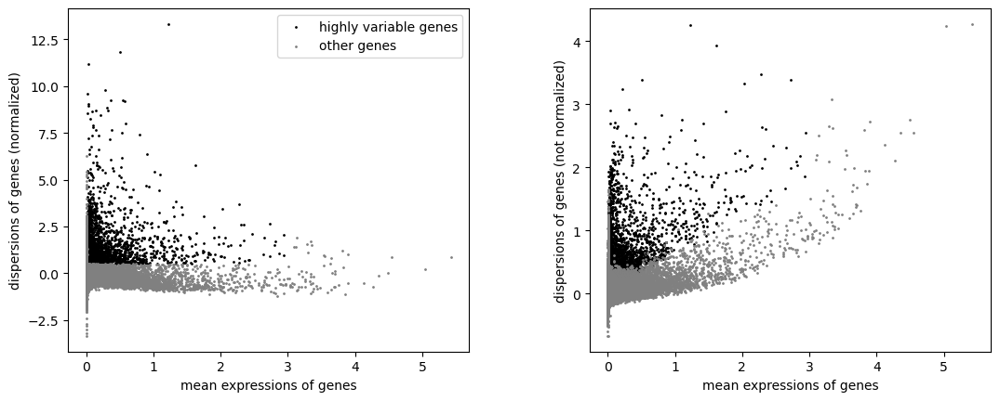

computing PCA
    with n_comps=50
    finished (0:00:15)


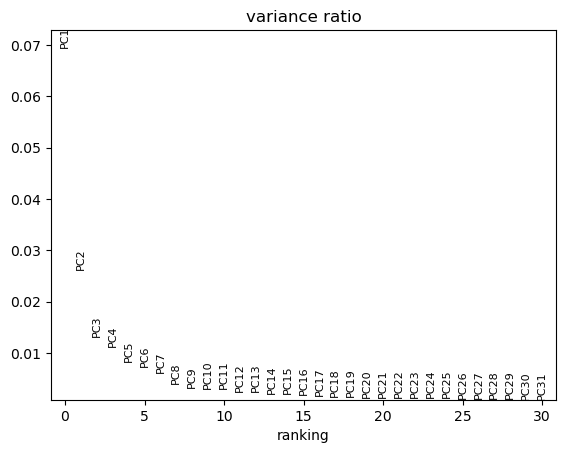

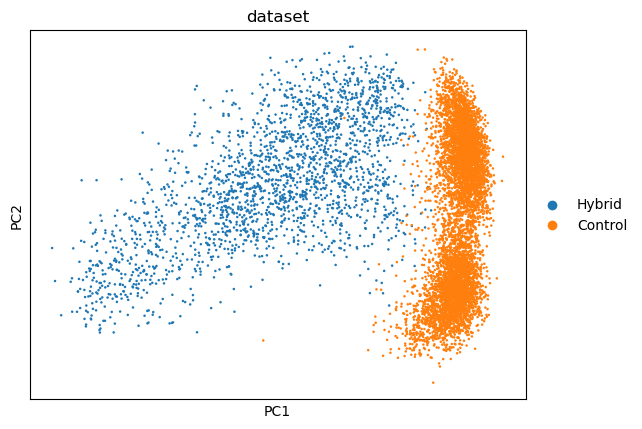

AnnData object with n_obs × n_vars = 9167 × 23037
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'filter_pass', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection

In [8]:
# adata.X = adata.layers['log_norm']

# sc.pp.highly_variable_genes(
#     adata,
#     batch_key='dataset',
# )

# print(f"Number of HVG: {adata.var['highly_variable'].sum()}")

# plt.rcdefaults()
# sc.pl.highly_variable_genes(adata)

# sc.pp.pca(
#     adata,
#     mask_var='filter_pass',
# )

# sc.pl.pca_variance_ratio(adata)
# sc.pl.pca(adata, color='dataset')

# adata

In [21]:
# adata.obs['assigned_condition'].value_counts()

assigned_condition
G1      4600
MYOD    2207
G2M     1210
S       1106
Name: count, dtype: int64

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:02)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished (0:01:23)
running Leiden clustering
    finished (0:00:00)


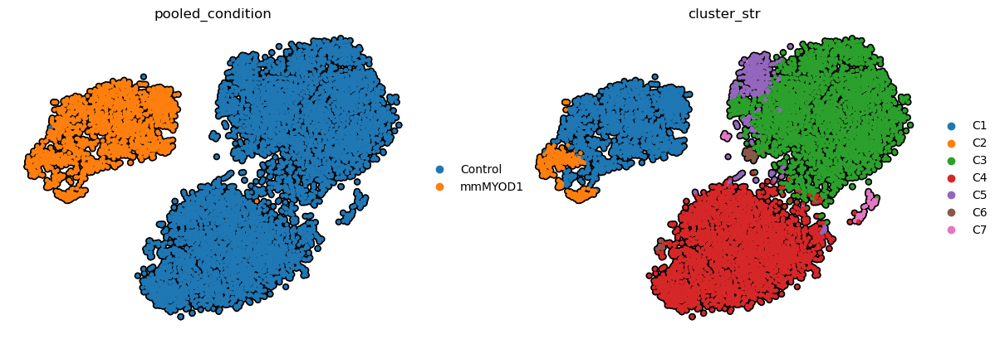

In [74]:
# sc.pp.neighbors(
#     adata,
#     n_neighbors=10,
# )


# sc.tl.tsne(
#     adata,
# )


# sc.tl.leiden(
#     adata,
#     resolution=0.5,
#     flavor="igraph",
#     n_iterations=-1, 
# )

# adata.obs['cluster_str'] = adata.obs['leiden'].apply(lambda x: f"C{str(int(x) + 1)}")

# sc.pl.tsne(
#     adata,
#     color=['pooled_condition', 'cluster_str'],
#     ncols=2,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
# )

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:02)
computing UMAP
    finished (0:00:16)
running Leiden clustering
    finished (0:00:00)


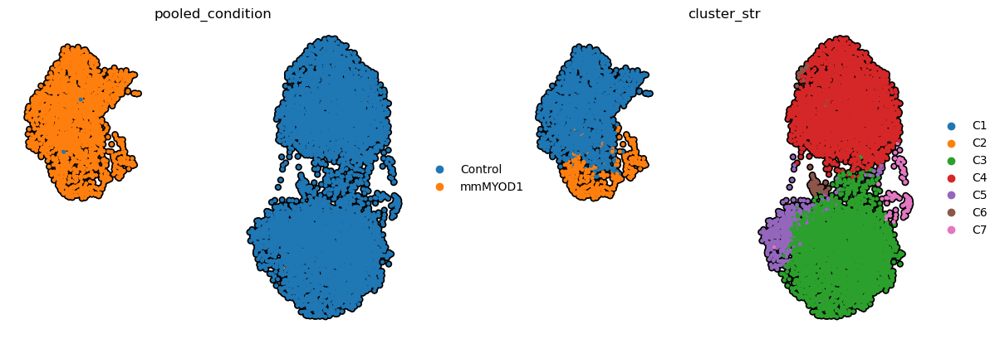

In [54]:
# sc.pp.neighbors(
#     adata,
#     n_neighbors=10,
# )

# sc.tl.umap(
#     adata,
#     # min_dist=0.2
# )

# sc.tl.leiden(
#     adata,
#     resolution=0.5,
#     flavor="igraph",
#     n_iterations=-1, 
# )

# adata.obs['cluster_str'] = adata.obs['leiden'].apply(lambda x: f"C{str(int(x) + 1)}")

# plt.rcdefaults()
# sc.pl.umap(
#     adata,
#     color=['pooled_condition', 'cluster_str'],#, 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_mt'],
#     ncols=2,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
# )

drawing single-cell graph using layout 'fa'
    finished (0:01:09)
running Leiden clustering
    finished (0:00:00)


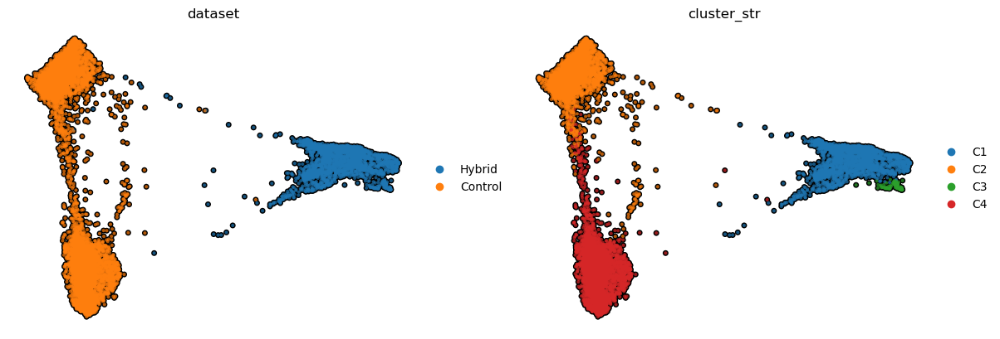

In [46]:
# sc.tl.draw_graph(adata)

# sc.tl.leiden(
#     adata,
#     resolution=0.4,
#     flavor="igraph",
#     n_iterations=-1, 
# )

# adata.obs['cluster_str'] = adata.obs['leiden'].apply(lambda x: f"C{str(int(x) + 1)}")


# sc.pl.draw_graph(
#     adata,
#     color=['dataset', 'cluster_str'],
#     size=35,
#     ncols=3,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
# )

computing batch balanced neighbors
	finished (0:00:02)
computing UMAP
    finished (0:00:26)
running Leiden clustering
    finished (0:00:00)


ValueError: zip() argument 2 is longer than argument 1

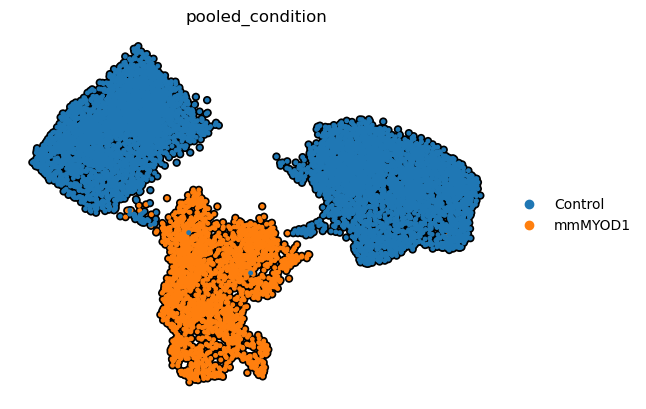

In [47]:
# sce.pp.bbknn(
#     adata,
#     batch_key='dataset',
#     neighbors_within_batch=20,
# )

# sc.tl.umap(
#     adata,
# )

# sc.tl.leiden(
#     adata,
#     resolution=0.4,
#     flavor="igraph",
#     n_iterations=-1, 
# )

# adata.obs['cluster_str'] = adata.obs['leiden'].apply(lambda x: f"C{str(int(x) + 1)}")

# plt.rcdefaults()
# sc.pl.umap(
#     adata,
#     color=['pooled_condition', 'cluster_str'],#, 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_mt'],
#     ncols=2,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
# )
    

2025-07-03 10:51:51,238 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
Thu Jul  3 10:51:51 2025 INFO Computing initial centroids with sklearn.KMeans...
2025-07-03 10:51:53,437 - harmonypy - INFO - sklearn.KMeans initialization complete.
Thu Jul  3 10:51:53 2025 INFO sklearn.KMeans initialization complete.
2025-07-03 10:51:53,491 - harmonypy - INFO - Iteration 1 of 10
Thu Jul  3 10:51:53 2025 INFO Iteration 1 of 10
2025-07-03 10:51:55,308 - harmonypy - INFO - Iteration 2 of 10
Thu Jul  3 10:51:55 2025 INFO Iteration 2 of 10
2025-07-03 10:51:57,110 - harmonypy - INFO - Converged after 2 iterations
Thu Jul  3 10:51:57 2025 INFO Converged after 2 iterations


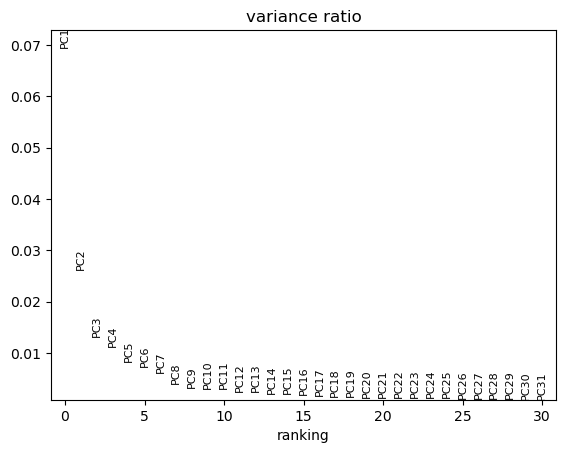

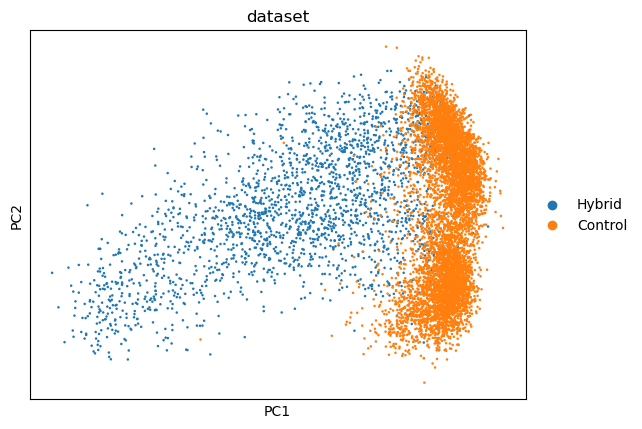

In [9]:
# sce.pp.harmony_integrate(adata, 'dataset')

# # Save original PCA space
# adata.obsm["X_pca_original"] = adata.obsm["X_pca"].copy()

# # Set Harmony-corrected PCA as the default for plotting and MAGIC imputation
# adata.obsm["X_pca"] = adata.obsm["X_pca_harmony"].copy()

# sc.pl.pca_variance_ratio(adata)
# sc.pl.pca(adata, color='dataset')

In [57]:
adata

AnnData object with n_obs × n_vars = 9167 × 23037
    obs: 'MYOD-fb_counts', 'PRRX1-fb_counts', 'PRRX1_MYOD-fb_counts', 'assigned_condition', 'total_fb_counts', 'condition_counts_rate', 'G1-fb_counts', 'G2M-fb_counts', 'S-fb_counts', 'dataset', 'total_reads', 'total_genes', 'pooled_condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', 'leiden', 'cluster_str'
    var: 'gene_id', 'gene_type', 'Chromosome', 'Start', 'End', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_counts', 'filter_pass', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'hig

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:02)
computing tSNE
    using sklearn.manifold.TSNE
    finished (0:01:21)
running Leiden clustering
    finished (0:00:00)


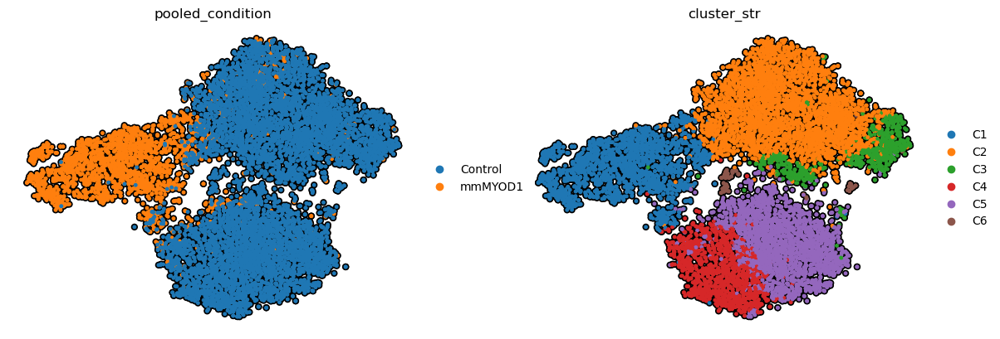

In [81]:
# sc.pp.neighbors(
#     adata,
#     n_neighbors=10,
# )


# sc.tl.tsne(
#     adata,
#     use_rep='X_pca_harmony',
# )


# sc.tl.leiden(
#     adata,
#     resolution=0.5,
#     flavor="igraph",
#     n_iterations=-1, 
# )

# adata.obs['cluster_str'] = adata.obs['leiden'].apply(lambda x: f"C{str(int(x) + 1)}")

# sc.pl.tsne(
#     adata,
#     color=['pooled_condition', 'cluster_str'],
#     ncols=2,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
# )

computing neighbors
    finished (0:00:25)
computing UMAP
    finished (0:00:14)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)


... storing 'leiden_hyb' as categorical


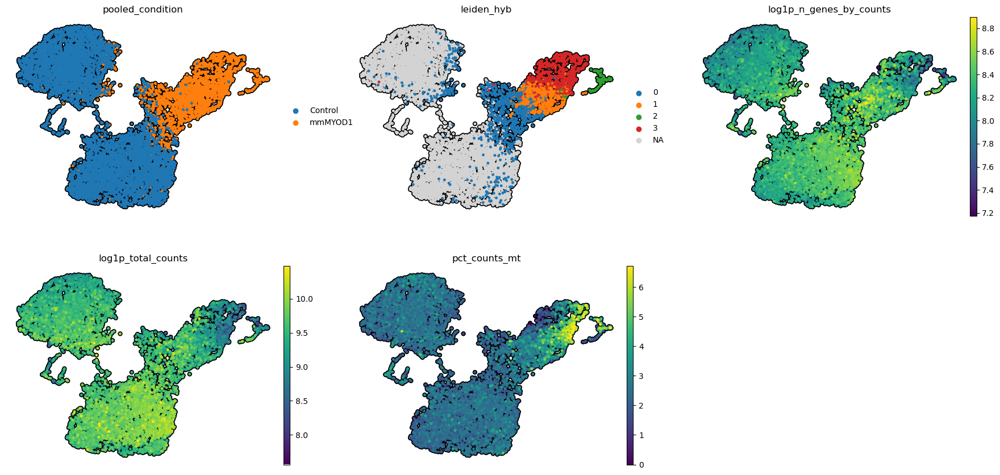

In [10]:
# bdata = adata.copy()


# sc.pp.neighbors(
#     bdata,
#     use_rep='X_pca_harmony',
#     n_neighbors=5,
# )

# sc.tl.umap(
#     bdata,
#     min_dist=0.25,
# )


# subset = bdata[bdata.obs['pooled_condition'].isin(['mmMYOD1'])].copy()
# sc.pp.neighbors(subset, n_neighbors=10)
# sc.tl.leiden(subset, resolution=0.25, flavor='igraph')

# bdata.obs['leiden_hyb'] = None
# bdata.obs.loc[subset.obs_names, 'leiden_hyb'] = subset.obs['leiden']

# # sc.tl.leiden(
# #     adata,
# #     resolution=0.001,
# #     restrict_to=('pooled_condition', ['mmMYOD1']),
# #     flavor="igraph",
# #     n_iterations=-1,
# #     key_added='leiden_hyb',
# # )

# # adata.obs['cluster_str'] = adata.obs['leiden'].apply(lambda x: f"C{str(int(x) + 1)}")

# plt.rcdefaults()
# sc.pl.umap(
#     bdata,
#     color=['pooled_condition', 'leiden_hyb', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_mt'],
#     ncols=3,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
# )

In [142]:
# bdata.obs['leiden_hyb'].value_counts()

leiden_hyb
0    880
3    663
1    567
2     97
Name: count, dtype: int64

... storing 'cluster_group' as categorical


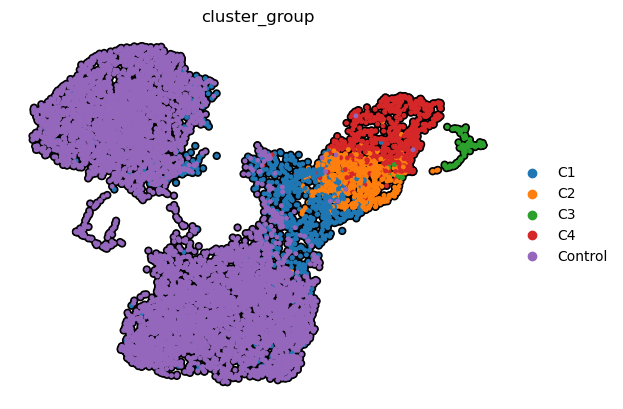

In [143]:
# cluster_map = {'0': 'C1', '1': 'C2', '2': 'C3', '3': 'C4'}

# bdata.obs['cluster_group'] = np.where(pd.isna(bdata.obs['leiden_hyb']), 'Control', bdata.obs['leiden_hyb'].map(cluster_map))

# plt.rcParams['figure.dpi'] = 200
# plt.rcParams['figure.figsize'] = 4, 4

# sc.pl.umap(
#     bdata,
#     color='cluster_group',
#     ncols=1,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
# )

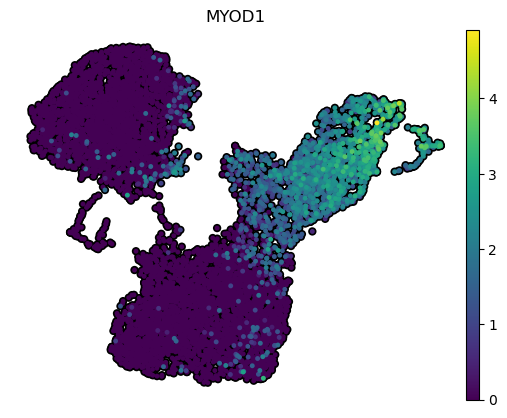

In [144]:
# plt.rcdefaults()
# sc.pl.umap(
#     bdata,
#     color='MYOD1',
#     ncols=1,
#     size=50,
#     add_outline=True,
#     outline_color=('k', 'k'),
#     frameon=False,
#     alpha=1,
#     layer='log_norm',
# )